In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [2]:
class BatmanState(TypedDict) : 
    #Input
    runs : int
    balls : int
    fours : int
    sixes : int
    
    #Calculations
    SR : float
    BpB : float
    Boud_Perc : float

    #Output
    Result : str

In [3]:
def cal_sr(state : BatmanState) : 
    sr = (state['runs']/state['balls']) * 100

    return {'SR' : sr}

In [4]:
def cal_bpb(state : BatmanState) :
    bpb = state['runs']/((state['fours']) + (state['sixes']))

    return {'BpB' : bpb}

In [5]:
def cal_percentage(state : BatmanState) :
    Boud_Perc = (((state['fours'] * 4) + (state['sixes'] * 6))/state['runs']) * 100

    return {'Boud_Perc' : Boud_Perc}

In [7]:
def summary(state : BatmanState) :
    summary = f"""
Strike Rate : {state['SR']} \n
Balls_Per_Boundary : {state['BpB']} \n
Boundary_Percentage : {state['Boud_Perc']}
"""
    
    return {'result' : summary}

In [10]:
graph = StateGraph(BatmanState)

#Nodes 
graph.add_node('Strike_Rate', cal_sr)
graph.add_node('BpB', cal_bpb)
graph.add_node('Bound_Per', cal_percentage)
graph.add_node('Summary', summary)

#Edges
graph.add_edge(START, 'Strike_Rate')
graph.add_edge(START, 'BpB')
graph.add_edge(START, 'Bound_Per')

graph.add_edge('Strike_Rate', 'Summary')
graph.add_edge('BpB', 'Summary')
graph.add_edge('Bound_Per', 'Summary')

graph.add_edge('Summary', END)

workflow = graph.compile()

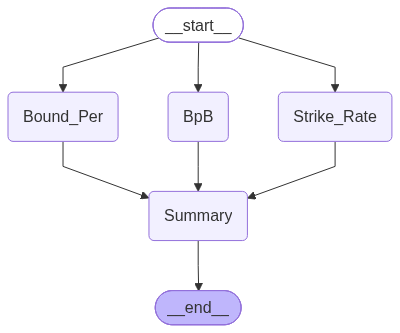

In [11]:
workflow

In [14]:
initial_state = {
    'runs' : 264,
    'balls' : 173,
    'fours' : 33,
    'sixes' : 9
}

workflow.invoke(initial_state)

{'runs': 264,
 'balls': 173,
 'fours': 33,
 'sixes': 9,
 'SR': 152.60115606936415,
 'BpB': 6.285714285714286,
 'Boud_Perc': 70.45454545454545}